# Practical 10: Dimensionality Reduction Using PCA

Compare the number of features, visualize reduced dimensions, and compare KNN classification before and after PCA. PCA retains at least 95% of the training-data variance.

Keep `Wine.csv` in the same folder as this notebook. Run cells from top to bottom.


Saved outputs were computed using the standard scikit-learn Wine reference dataset (178 samples, 13 measurements, class labels 1–3). The original Wine.csv was not supplied. To rerun, keep your Wine.csv in this notebook's folder; results may differ if its contents differ.

In [1]:
# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

In [2]:
# 2. Load and inspect the dataset
df = pd.read_csv("Wine.csv")

print("Number of samples:", df.shape[0])
print("Number of input features:", df.shape[1] - 1)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.head()

Number of samples: 178
Number of input features: 13
Missing values: 0
Duplicate rows: 0


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,Customer_Segment
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,1
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,1
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,1
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,1
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,1


In [3]:
# 3. Separate inputs and target
X = df.drop("Customer_Segment", axis=1)
y = df["Customer_Segment"]

print("Input shape:", X.shape)
print("Target classes:", sorted(y.unique()))

Input shape: (178, 13)
Target classes: [np.int64(1), np.int64(2), np.int64(3)]


In [4]:
# 4. Split before scaling and PCA
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (142, 13)
Testing shape: (36, 13)


In [5]:
# 5. Learn scaling from training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
# 6. Train and evaluate KNN before PCA
model = KNeighborsClassifier()
model.fit(X_train_scaled, y_train)

pred_before = model.predict(X_test_scaled)
acc_before = accuracy_score(y_test, pred_before)

print("Accuracy before PCA:", round(acc_before * 100, 2), "%")
print(classification_report(y_test, pred_before))

Accuracy before PCA: 97.22 %
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       1.00      0.93      0.96        14
           3       0.91      1.00      0.95        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



In [7]:
# 7. Retain at least 95% of variance
# Learn PCA from training data only.
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Features before PCA:", X_train_scaled.shape[1])
print("Components after PCA:", pca.n_components_)
print("Variance retained (%):",
      round(pca.explained_variance_ratio_.sum() * 100, 2))

pc_names = [f"PC{i + 1}" for i in range(pca.n_components_)]
pca_df = pd.DataFrame(X_train_pca, columns=pc_names)
pca_df.head()

Features before PCA: 13
Components after PCA: 10
Variance retained (%): 96.24


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
0,1.472343,0.734251,0.454892,-1.035948,0.549676,-0.721626,0.096645,-0.953128,-0.150457,-1.231793
1,2.649709,1.230211,1.500462,-0.748548,-0.108490,0.452007,-0.429117,0.645468,0.793138,0.105283
2,1.888788,0.792472,-0.099175,-1.006960,-0.772992,-0.627378,-0.251475,-1.113552,0.400011,0.045740
3,2.211159,0.753458,-0.792728,-1.188320,-0.589930,-0.258732,-0.127602,0.126871,1.020481,-0.058697
4,-2.817571,1.645688,-0.385180,0.145550,-0.562510,0.563510,-0.438572,-0.043290,-0.088750,0.215624


PCA creates new features by combining the original measurements. The classifier below uses **all** selected components. The scatter plot displays only PC1 and PC2; those two alone do not necessarily retain 95% of the variance. Target labels stay separately in `y_train` and `y_test`.

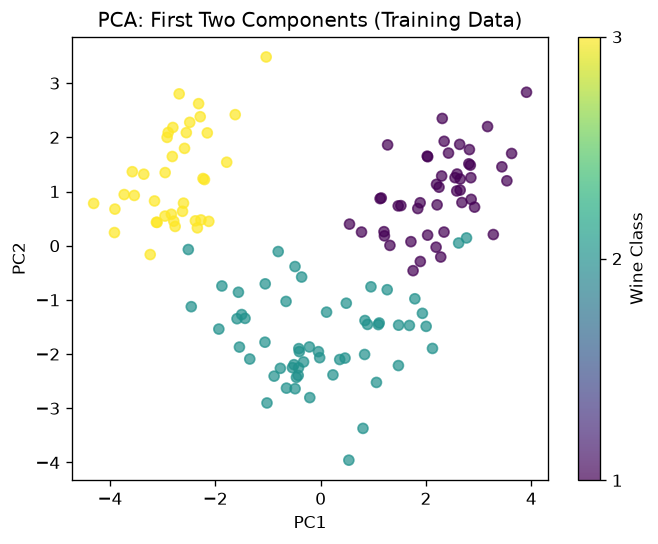

In [8]:
# 8. Visualize the first two components
plt.scatter(
    X_train_pca[:, 0], X_train_pca[:, 1],
    c=y_train, cmap="viridis", alpha=0.7
)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA: First Two Components (Training Data)")
plt.colorbar(label="Wine Class", ticks=sorted(y.unique()))
plt.show()

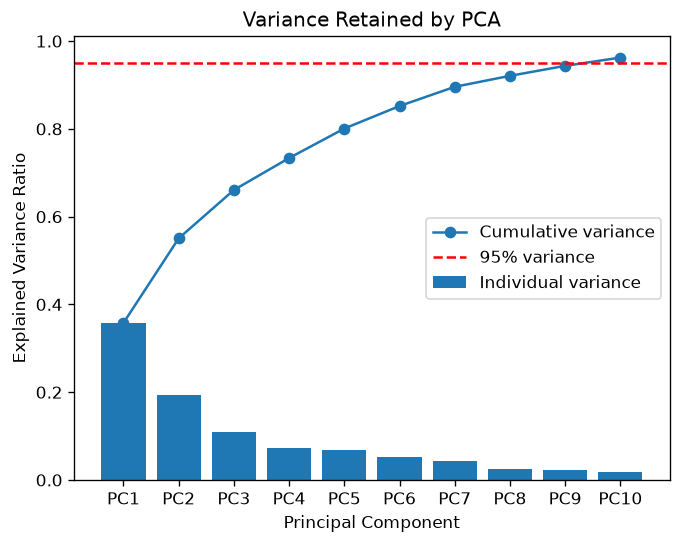

In [9]:
# 9. Show variance retained by the selected components
variance = pca.explained_variance_ratio_
cumulative = variance.cumsum()

plt.bar(pc_names, variance, label="Individual variance")
plt.plot(pc_names, cumulative, marker="o", label="Cumulative variance")
plt.axhline(0.95, color="red", linestyle="--", label="95% variance")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("Variance Retained by PCA")
plt.legend()
plt.show()

In [10]:
# 10. Train KNN using ALL selected components
model_pca = KNeighborsClassifier(n_neighbors=5)
model_pca.fit(X_train_pca, y_train)

pred_after = model_pca.predict(X_test_pca)
acc_after = accuracy_score(y_test, pred_after)

print("Accuracy after PCA:", round(acc_after * 100, 2), "%")
print(classification_report(y_test, pred_after))

Accuracy after PCA: 97.22 %
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       1.00      0.93      0.96        14
           3       0.91      1.00      0.95        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



                  Method  Input columns  Test accuracy (%)
              Before PCA             13              97.22
After PCA (95% variance)             10              97.22


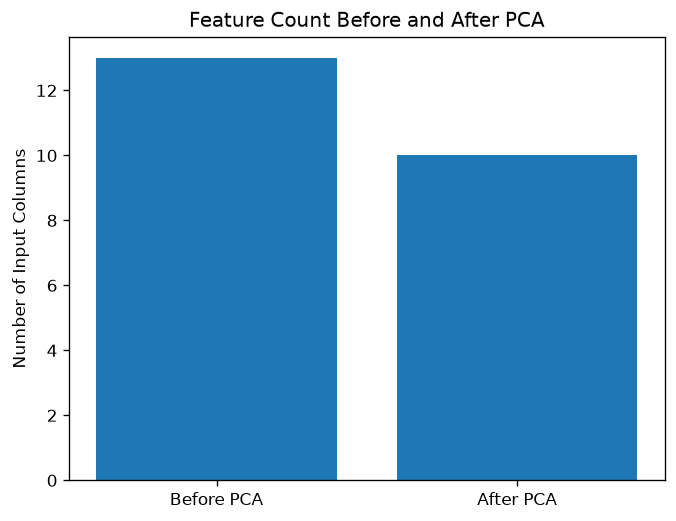

In [11]:
# 11. Final comparison on the same test samples
comparison = pd.DataFrame({
    "Method": ["Before PCA", "After PCA (2 Components)"],
    "Input columns": [X_train_scaled.shape[1], X_train_pca.shape[1]],
    "Test accuracy (%)": [
        round(acc_before * 100, 2),
        round(acc_after * 100, 2)
    ]
})
print(comparison.to_string(index=False))

plt.bar(["Before PCA", "After PCA"],
        [X_train_scaled.shape[1], X_train_pca.shape[1]])
plt.ylabel("Number of Input Columns")
plt.title("Feature Count Before and After PCA")
plt.show()

Compare the printed test accuracies to describe PCA's impact on classification. Retaining 95% of variance does not guarantee 95% accuracy or improved accuracy. Both models use the same test samples and the same KNN settings.